In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
import os
import random
#!pip install "transformers<5"
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import joblib
import shap
#import transformers
#from transformers import BertTokenizer, TFBertModel

In [2]:
scaler_f_dir = '/content/drive/MyDrive/ml/XAI/scaler_f.pkl'
scaler_t_dir = '/content/drive/MyDrive/ml/XAI/scaler_t.pkl'
encoder_dir = '/content/drive/MyDrive/ml/XAI/vae_enc_smoteen.keras'
classifier_dir = '/content/drive/MyDrive/ml/XAI/vae_classifier_smoteen.keras'
labels_dir = '/content/drive/MyDrive/ml/n_datasets/y_test.npy'
data = '/content/drive/MyDrive/ml/XAI/test_features_sequences.csv'

In [3]:
scaler_f = joblib.load(scaler_f_dir)
scaler_t = joblib.load(scaler_t_dir)
enc = keras.models.load_model(encoder_dir)
classifier = keras.models.load_model(classifier_dir)
df = pd.read_csv(data)
y_test = np.load(labels_dir)
#df

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.7.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [4]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()

In [5]:
from keras import models
@tf.function
def sampling_reparameterization(distribution_params) -> tf.Tensor:
    mean, log_var = distribution_params
    epsilon = tf.random.normal(shape=tf.shape(mean), mean=0., stddev=1.)
    z = mean + tf.exp(log_var / 2) * epsilon
    return z

@tf.function
def binary_entropy(p, eps=1e-7) -> tf.Tensor:
    p = tf.clip_by_value(p, eps, 1. - eps)
    return -(p * tf.math.log(p) + (1 - p) * tf.math.log(1 - p))

class UQ_VAE(models.Model):
    def __init__(self, encoder_dir, classifier_dir):
        super(UQ_VAE, self).__init__()
        self.encoder = models.load_model(encoder_dir)
        self.classifier = models.load_model(classifier_dir)
        self.logits_classifier = models.Model(inputs=self.classifier.input, outputs=[self.classifier.layers[-1].output, self.classifier.layers[-2].output])

    @tf.function
    def _mc_forward_pass(self, x, S):
        if self.encoder is None or self.classifier is None:
            raise ValueError("Los modelos encoder y classifier no han sido cargados correctamente.")
        mean, log_var = self.encoder(x, training=True)  # (B, 128)
        mean = tf.expand_dims(mean, axis=1)        # (B, 1, 128)
        log_var = tf.expand_dims(log_var, axis=1)  # (B, 1, 128)
        # Repetimos S veces
        mean = tf.repeat(mean, repeats=S, axis=1)      # (B, S, 128)
        log_var = tf.repeat(log_var, repeats=S, axis=1)
        z = sampling_reparameterization((mean, log_var))  # (B, S, 128)
        B = tf.shape(z)[0]
        z_flat = tf.reshape(z, (-1, 128))  # (B*S, 128)

        p, logits = self.logits_classifier(z_flat, training=True)  # (B*S, 1)
        p = tf.reshape(p, (B, S))               # (B, S)
        logits = tf.reshape(logits, (B, S))     # (B, S)
        p_mean = tf.reduce_mean(p, axis=1)      # (B,)
        logits_mean = tf.reduce_mean(logits, axis=1)
        u_aleatoric = tf.reduce_mean(binary_entropy(p), axis=1)  # (B,)
        return p_mean, logits_mean, u_aleatoric

    def predict_with_uncertainty(self, dataset, T=20, S=20):
        all_p_mean = []
        all_logits_mean = []
        all_u_aleatoric = []
        for x_batch in dataset:
            batch_p = []
            batch_logit = []
            batch_u_a = []
            for _ in range(T):
                p_mean_t, logits_mean_t, u_a_t = self._mc_forward_pass(x_batch, S)
                batch_p.append(p_mean_t)
                batch_logit.append(logits_mean_t)
                batch_u_a.append(u_a_t)

            # Stack epistémico
            batch_p = tf.stack(batch_p, axis=0)        # (T, B)
            batch_logit = tf.stack(batch_logit, axis=0) # (T, B)
            batch_u_a = tf.stack(batch_u_a, axis=0)    # (T, B)

            u_aleatoric = tf.reduce_mean(batch_u_a, axis=0)  # (B,)
            logits_mean = tf.reduce_mean(batch_logit, axis=0)
            p_marginal = tf.reduce_mean(batch_p, axis=0)
            u_total = binary_entropy(p_marginal)
            u_epistemic = u_total - u_aleatoric

            all_p_mean.append(p_marginal)
            all_logits_mean.append(logits_mean)
            all_u_aleatoric.append((u_total, u_aleatoric, u_epistemic))

        return (
            tf.concat(all_p_mean, axis=0),
            tf.concat(all_logits_mean, axis=0),
            tuple(tf.concat(x, axis=0) for x in zip(*all_u_aleatoric))
        )

In [6]:
uq = UQ_VAE(encoder_dir, classifier_dir)

In [7]:
!pip install "transformers<5"
import transformers
from transformers import BertTokenizer, TFBertModel

In [8]:
model_name = "Rostlab/prot_bert"
tokenizer = BertTokenizer.from_pretrained(model_name, do_lower_case=False)
model = TFBertModel.from_pretrained(model_name, from_pt=True)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFBertModel: ['cls.predictions.transform.dense.bias', 'cls.predictions.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.decoder.weight', 'cls.seq_relationship.bias', 'cls.predictions.transform.dense.weight', 'cls.

In [9]:
mean_tf = tf.constant(scaler_t.mean_, dtype=tf.float32)
scale_tf = tf.constant(scaler_t.scale_, dtype=tf.float32)

#def standardize(x):
#    return (x - mean_tf) / scale_tf

def standardize(tensor):
    return (tensor - mean_tf) / (scale_tf)

## Sequences selection based of uncertainty level

In [10]:
test = tf.data.Dataset.from_tensor_slices(
    (df.iloc[:,:1024].to_numpy().astype('float32'), df.iloc[:,1024:-1].to_numpy().astype('float32'))
).batch(64)

In [11]:
predictions, logits, uncertainties = uq.predict_with_uncertainty(test)

In [12]:
u_total = uncertainties[0].numpy()

In [13]:

positive_class_indices = np.where(y_test == 1)[0]
uncertainties_positive = u_total[positive_class_indices]

max_uncertainty_relative_idx = np.argmax(uncertainties_positive)
min_uncertainty_relative_idx = np.argmin(uncertainties_positive)
idx_highest_uncertainty_positive = positive_class_indices[max_uncertainty_relative_idx]
idx_lowest_uncertainty_positive = positive_class_indices[min_uncertainty_relative_idx]

print(f"Index of the sequence with highest uncertainty (positive class): {idx_highest_uncertainty_positive}")
print(f"Value of highest uncertainty: {u_total[idx_highest_uncertainty_positive]:.4f}")
print(f"Index of the sequence with lowest uncertainty (positive class): {idx_lowest_uncertainty_positive}")
print(f"Value of lowest uncertainty: {u_total[idx_lowest_uncertainty_positive]:.4f}")

Index of the sequence with highest uncertainty (positive class): 898
Value of highest uncertainty: 0.6745
Index of the sequence with lowest uncertainty (positive class): 344
Value of lowest uncertainty: 0.0000


## SHAP Application

In [14]:
df['processed_sequence'] = df['sequence'].apply(lambda s: " ".join(list(s)))

In [15]:
df_test = pd.read_csv('/content/drive/MyDrive/ml/Machine_Learning/datasets/test_descriptores.csv')
columns = list(df_test.columns[4:])

In [16]:
def seq_to_inputs(seq_list):
  tok = tokenizer(seq_list, return_tensors="tf", padding='max_length', truncation=True, max_length=512)
  input_ids = tf.cast(tok["input_ids"], tf.int32)
  attention_mask = tf.cast(tok["attention_mask"], tf.int32)
  transformer_layer = model.bert if hasattr(model, "bert") else model
  inputs_emb = tf.cast(transformer_layer.embeddings(input_ids), tf.float32)
  return inputs_emb, attention_mask

In [17]:
N_BG = 80
half_bg = N_BG // 2

# Obtener índices de cada clase
pos_indices = np.where(y_test == 1)[0]
neg_indices = np.where(y_test == 0)[0]

# Excluir los índices usados para las explicaciones detalladas
excluded_pos = {idx_highest_uncertainty_positive, idx_lowest_uncertainty_positive}
pos_indices_clean = [i for i in pos_indices if i not in excluded_pos]

# Seleccionar índices balanceados aleatoriamente
selected_pos = np.random.choice(pos_indices_clean, half_bg, replace=False)
selected_neg = np.random.choice(neg_indices, half_bg, replace=False)

bg_indices = np.concatenate([selected_pos, selected_neg])
np.random.shuffle(bg_indices) # Mezclar para evitar sesgo de orden

# Obtener datos para el background
bg_sequences = df.iloc[bg_indices, -1].tolist()
bg_embeds, bg_mask = seq_to_inputs(bg_sequences)
bg_desc = (df.iloc[bg_indices, 1024:-2].to_numpy()).reshape((-1, 887))

print(f"Background seleccionado con {len(bg_indices)} muestras (Balanceadas: {half_bg}+ y {half_bg}-)")

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.


Background seleccionado con 80 muestras (Balanceadas: 40+ y 40-)


In [18]:

pad_token_id = tokenizer.pad_token_id
pad_embedding = model.bert.embeddings(tf.constant([[pad_token_id]]))[0, 0, :]

class ShapMultimodalWrapper(tf.keras.Model):
    def __init__(self, protbert_model, encoder, classifier, pad_embed_vector, standardize_f):
        super().__init__()
        self.protbert_model = protbert_model
        self.encoder = encoder
        self.classifier = classifier
        self.pad_embed_vector = pad_embed_vector
        self.standardize_fn = standardize_f
    @tf.function
    def call(self, inputs):
        inputs_embeds = inputs[0]
        descriptores = inputs[1]
        diferencia = tf.reduce_sum(tf.abs(inputs_embeds - self.pad_embed_vector), axis=-1)

        # Si la diferencia es casi 0, es un token de padding.
        # máscara: 1 para texto real, 0 para padding.
        attention_mask = tf.cast(diferencia > 1e-6, tf.int32)

        bert_output = self.protbert_model(
            input_ids=None,
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            training=False
        )

        cls_emb = bert_output.last_hidden_state[:, 0, :]
        scaled = self.standardize_fn(cls_emb)
        mean, _ = self.encoder([scaled, descriptores], training=False)
        final_out = self.classifier(mean, training=False)
        return final_out

wrapper_model = ShapMultimodalWrapper(
    model,
    enc,
    classifier,
    pad_embedding,
    standardize
)
inputs_embeds_tensor = tf.keras.Input(shape=(bg_embeds.shape[1], bg_embeds.shape[2]), dtype=tf.float32, name='inputs_embeds')
descriptors_tensor = tf.keras.Input(shape=(bg_desc.shape[1],), dtype=tf.float32, name='descriptors')
outputs = wrapper_model([inputs_embeds_tensor, descriptors_tensor])
shap_explainer_model = tf.keras.Model(
    inputs=[inputs_embeds_tensor, descriptors_tensor],
    outputs=outputs,
    name="ShapExplainerModel"
)

In [19]:
"""
class CustomShapModel(tf.keras.Model):
    def __init__(self, transformer_model_instance, encoder_model, classifier_model, standardization_function, **kwargs):
        super().__init__(**kwargs)
        self.transformer_layer = transformer_model_instance.bert if hasattr(transformer_model_instance, "bert") else transformer_model_instance
        self.encoder = encoder_model
        self.classifier = classifier_model
        self.standardize_fn = standardization_function

    def call(self, inputs):
        inputs_embeds, attention_mask, descriptors = inputs
        outputs = self.transformer_layer(
            input_ids=None,
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            training=False
        )
        cls_emb = outputs.last_hidden_state[:, 0, :]
        scaled = self.standardize_fn(cls_emb)
        mean, _ = self.encoder([cls_emb, descriptors])
        final_out = self.classifier(mean)
        return final_out

# Instantiate the custom model
custom_shap_model_instance = CustomShapModel(
    transformer_model_instance=model, # `model` is the TFBertModel instance
    encoder_model=enc,
    classifier_model=classifier,
    standardization_function=standardize
)

# Define explicit Input tensors for the functional model
inputs_embeds_tensor = tf.keras.Input(shape=(bg_embeds.shape[1], bg_embeds.shape[2]), dtype=tf.float32, name='inputs_embeds')
attention_mask_tensor = tf.keras.Input(shape=(bg_mask.shape[1],), dtype=tf.int32, name='attention_mask')
descriptors_tensor = tf.keras.Input(shape=(bg_desc.shape[1],), dtype=tf.float32, name='descriptors')

# Call the custom_shap_model_instance with the Input tensors
output_tensor = custom_shap_model_instance([inputs_embeds_tensor, attention_mask_tensor, descriptors_tensor])

# Create a new functional Keras model that explicitly defines its inputs and outputs
shap_explainer_model = tf.keras.Model(
    inputs=[inputs_embeds_tensor, attention_mask_tensor, descriptors_tensor],
    outputs=output_tensor,
    name="ShapExplainerModel"
)
"""
explainer = shap.GradientExplainer(
    shap_explainer_model,
    data=[bg_embeds, bg_desc],
    batch_size=4
)

### Lowest uncertainty chitinase sample

In [20]:
i = idx_lowest_uncertainty_positive

feat = df.iloc[i,1024:-2].to_numpy()
feat = feat.reshape((-1, 887))
feat.shape
seq = df.iloc[i,-1]
if len(seq.split(' ')) > 512:
    seq = ' '.join(seq.split(' ')[:512])

In [21]:
tf.experimental.numpy.experimental_enable_numpy_behavior()

# Ahora seq_to_inputs devolverá (1, 512, 1024) gracias a la modificación anterior
test_embeds, test_mask = seq_to_inputs(seq)
test_desc = (df.iloc[i,1024:-2].to_numpy()).reshape((-1, 887))

# SHAP GradientExplainer prefiere tensores de TF cuando el modelo es de Keras/TF
shap_values = explainer.shap_values(
    [test_embeds, test_desc ]
)

In [ ]:
len(shap_values)

2

In [22]:
token_shap_values = np.sum(shap_values[0].reshape((512, 1024)), axis=-1)

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

3/3 ━━━━━━━━━━━━━━━━━━━━ 42s 9s/step


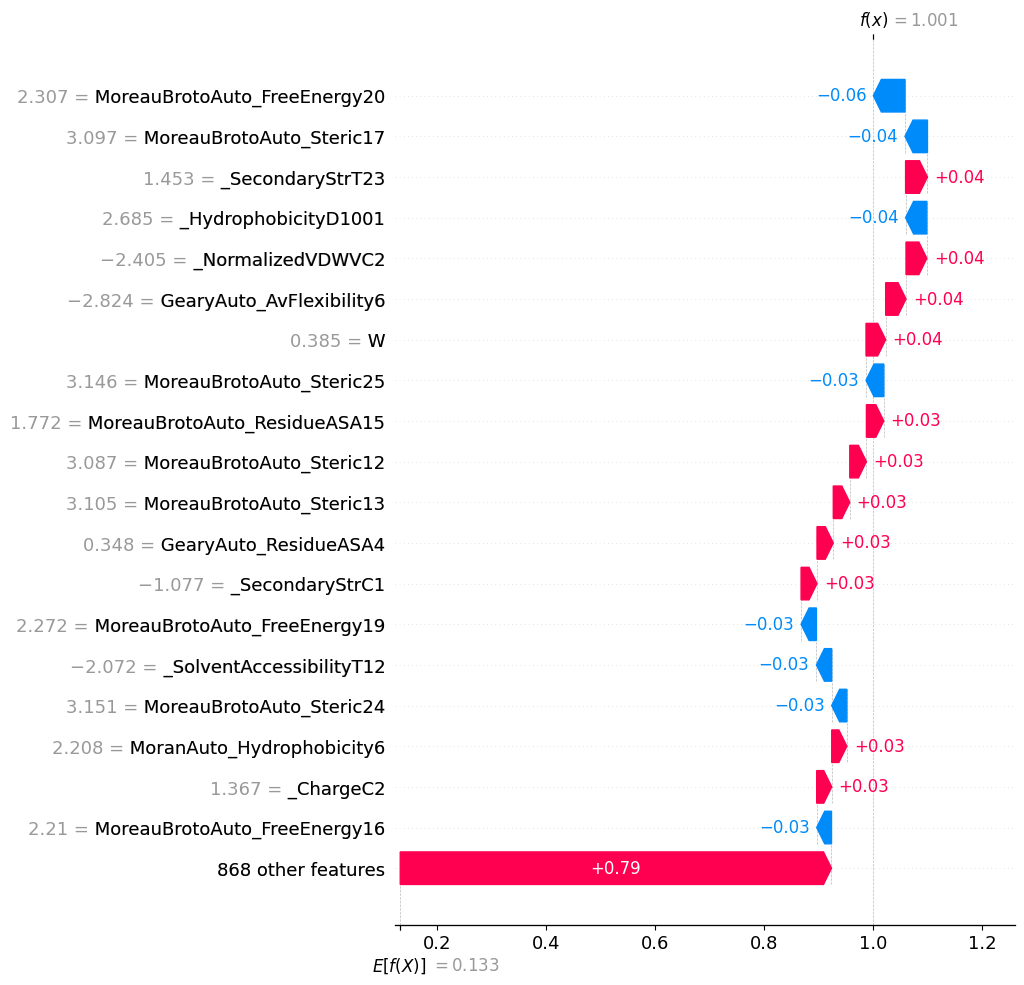

In [24]:
# 1. Calculate expected_value manually if not present
# We get the model output for the background samples
bg_preds = shap_explainer_model.predict([bg_embeds, bg_desc])
# The expected value is the mean of the background predictions
# Assuming binary classification, we take the mean across the samples for the output
manual_expected_value = np.mean(bg_preds, axis=0)[0]

# 2. Waterfall plot for descriptors (shap_values[1])
desc_values = shap_values[1].flatten()

shap.waterfall_plot(
    shap.Explanation(
        values=desc_values,
        base_values=manual_expected_value,
        data=test_desc.flatten(),
        feature_names=columns
    ),
    max_display=20
)

In [25]:
from IPython.display import HTML


tokens = tokenizer.convert_ids_to_tokens(tokenizer(seq, truncation=True, max_length=512)['input_ids'])
filtered_tokens, filtered_attributions = [], []
for tok_str, attr in zip(tokens, token_shap_values):
    if tok_str not in tokenizer.all_special_tokens:
        filtered_tokens.append(tok_str)
        filtered_attributions.append(float(attr))
valid_token_shap = token_shap_values[:len(tokens)]

def plot_attributions(tokens, attributions):
    """
    Plots the original sequence with token contributions highlighted using a color gradient.

    Args:
        :tokens (list): List of tokens (strings).
        :attributions (np.ndarray): Array of attribution scores for each token.
    """
    if len(tokens) != len(attributions):
        raise ValueError("Tokens and attributions must have the same length.")

    max_abs_attr = np.max(np.abs(attributions))
    html_output = "<div style='font-family: Arial, sans-serif; font-size: 1.1em; line-height: 1.6; padding: 10px; border: 1px solid #eee; border-radius: 5px; background-color: #ddd;'>"

    for token, attr in zip(tokens, attributions):
        if max_abs_attr == 0:
            alpha = 0
        else:
            # Scale attribution to [-1, 1]
            scaled_attr = attr / max_abs_attr
            alpha = abs(scaled_attr) # Opacity based on absolute value
            alpha -= alpha/9
            alpha += 0.05

        if attr > 0:
            # Green shades for positive contributions
            color_str = f"rgba(0, 255, 0, {alpha})" # Darker green
        elif attr < 0:
            # Red shades for negative contributions
            color_str = f"rgba(255, 0, 0, {alpha})" # Red
        else:
            # Transparent for zero contribution
            color_str = "rgba(255, 255, 255, 0)"

        html_output += f"<span style='background-color: {color_str}; padding: 3px 5px; color: #fff; margin: 0 1px; border-radius: 3px; display: inline-block; white-space: pre;'>{token}</span>"
    html_output += "</div>"
    return HTML(html_output)

plot_attributions(filtered_tokens, filtered_attributions)

In [26]:
sum(filtered_attributions), sum(desc_values)

(-0.06631036219583103, np.float64(0.868145507474992))

### Highest uncertainty chitinase sample

3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step


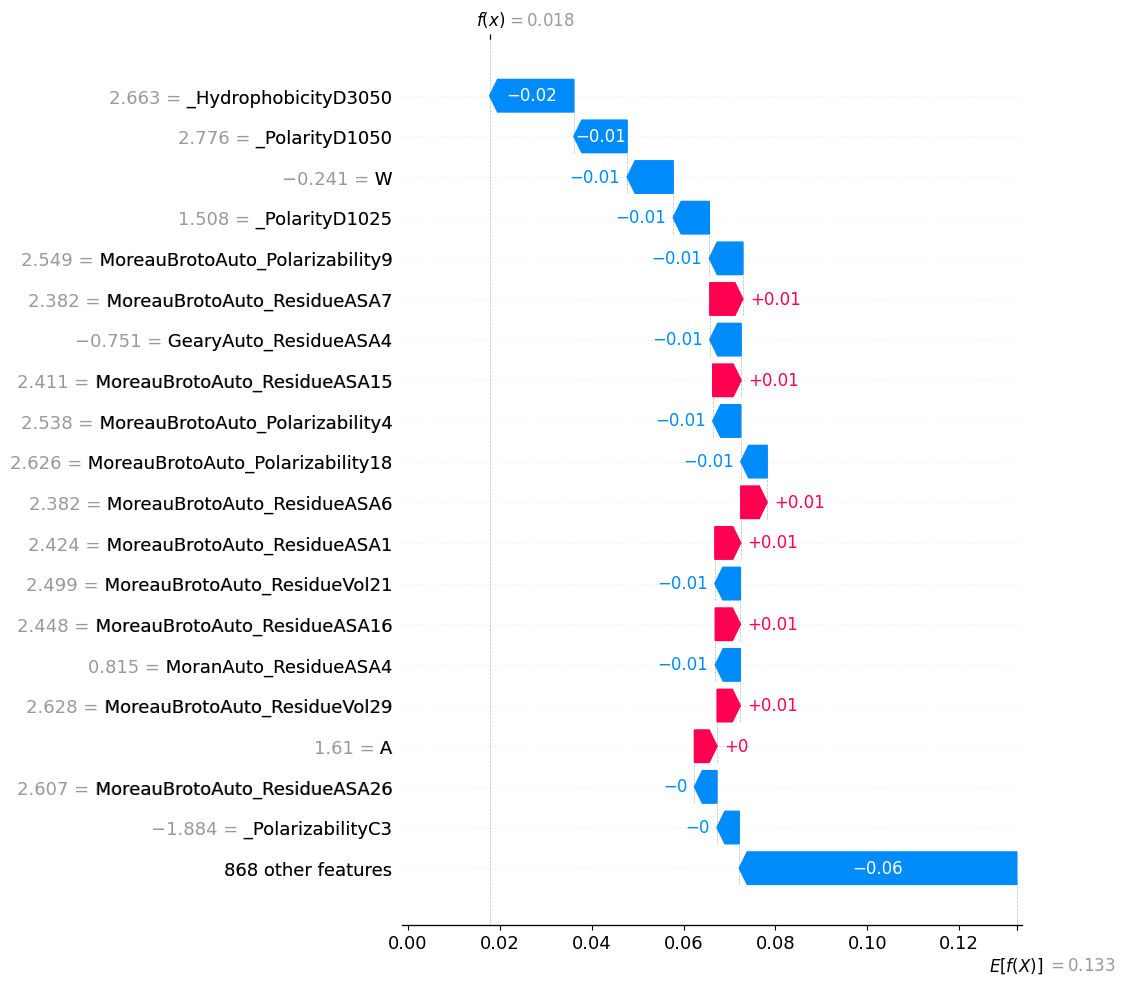

In [27]:
i = idx_highest_uncertainty_positive

feat = df.iloc[i,1024:-2].to_numpy()
feat = feat.reshape((-1, 887))
feat.shape
seq = df.iloc[i,-1]
if len(seq.split(' ')) > 512:
    seq = ' '.join(seq.split(' ')[:512])
test_embeds, test_mask = seq_to_inputs(seq)
test_desc = (df.iloc[i,1024:-2].to_numpy()).reshape((-1, 887))
test_embeds = test_embeds.numpy()


shap_values = explainer.shap_values(
    [test_embeds, test_desc]
)
token_shap_values = np.sum(shap_values[0].reshape((512, 1024)), axis=-1)
bg_preds = shap_explainer_model.predict([bg_embeds, bg_desc])
manual_expected_value = np.mean(bg_preds, axis=0)[0]
desc_values = shap_values[1].flatten()

shap.waterfall_plot(
    shap.Explanation(
        values=desc_values,
        base_values=manual_expected_value,
        data=test_desc.flatten(),
        feature_names=columns
    ),
    max_display=20
)

In [28]:
tokens = tokenizer.convert_ids_to_tokens(tokenizer(seq, truncation=True, max_length=512)['input_ids'])
filtered_tokens, filtered_attributions = [], []
for tok_str, attr in zip(tokens, token_shap_values):
    if tok_str not in tokenizer.all_special_tokens:
        filtered_tokens.append(tok_str)
        filtered_attributions.append(float(attr))
valid_token_shap = token_shap_values[:len(tokens)]
plot_attributions(filtered_tokens, filtered_attributions)

In [29]:
sum(filtered_attributions), sum(desc_values)

(-0.027081406351265287, np.float64(-0.1147251598171124))

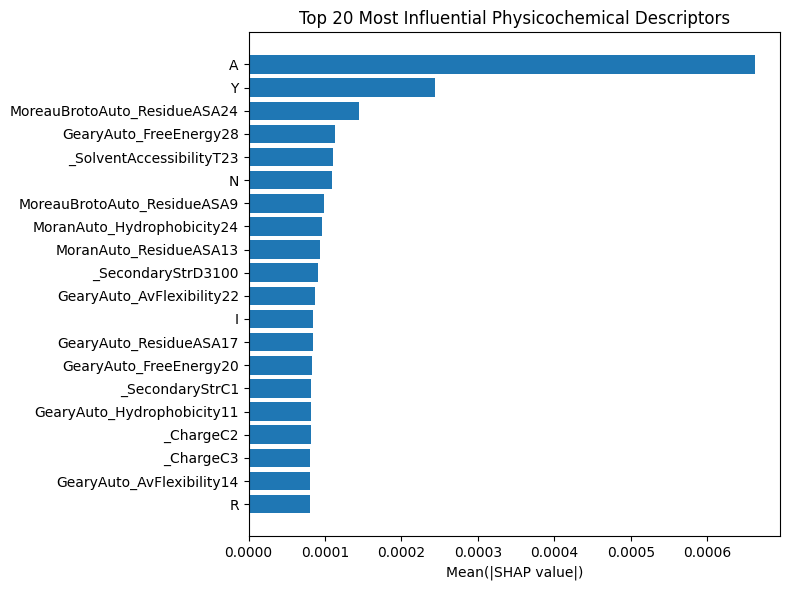

In [ ]:
mean_abs_shap = np.mean(np.abs(shap_feat), axis=0)

top_k = 20
# Flatten mean_abs_shap to a 1D array before argsort to get correct 1D indices
top_idx = np.argsort(mean_abs_shap.flatten())[::-1][:top_k]

top_features = np.array(columns)[top_idx] # This will now correctly be a 1D array of strings
top_values = mean_abs_shap.flatten()[top_idx] # This will now correctly be a 1D array of floats

plt.figure(figsize=(8, 6))
plt.barh(top_features[::-1], top_values[::-1])
plt.xlabel("Mean(|SHAP value|)")
plt.title("Top 20 Most Influential Physicochemical Descriptors")
plt.tight_layout()
plt.show()

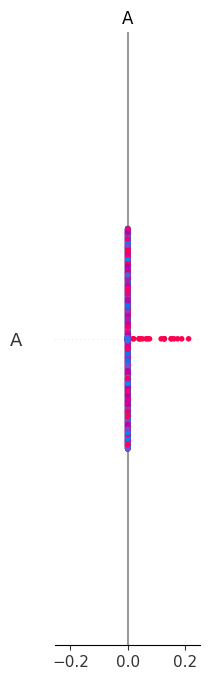

In [ ]:

# SOLO top 20
shap.summary_plot(
    shap_feat[:, top_idx],
    X_test_feat[:, top_idx],
    feature_names=top_features,
    show=True
)

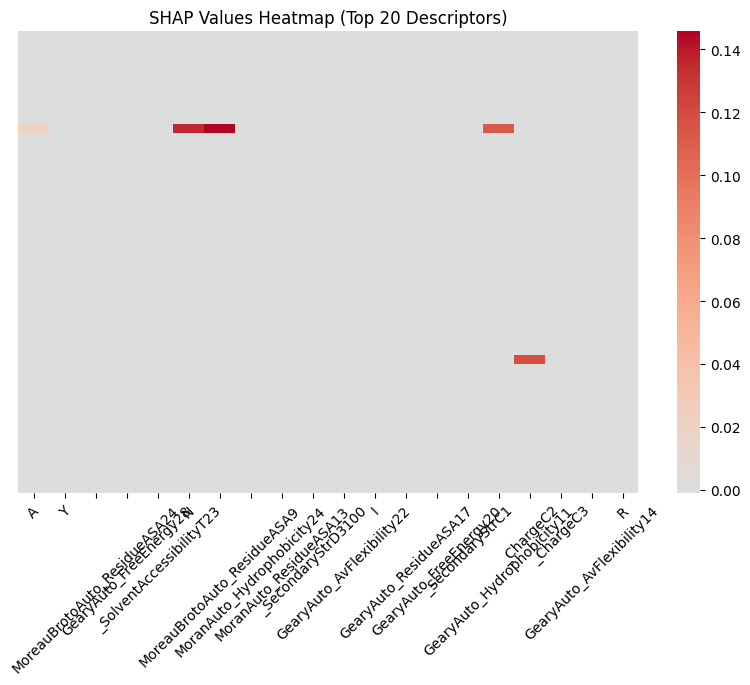

In [ ]:

plt.figure(figsize=(10,6))
sns.heatmap(
    shap_feat[:50, top_idx].squeeze(),  # primeras 50 muestras, y se elimina la dimensión extra
    cmap="coolwarm",
    center=0,
    yticklabels=False,
    xticklabels=top_features
)
plt.title("SHAP Values Heatmap (Top 20 Descriptors)")
plt.xticks(rotation=45)
plt.show()

In [ ]:
i = 0
for j in range(len(y_1)):
  if y_1[j] == 1:
    i = j
    break

shap_values = explainer.shap_values(
    X_test_feat[i:i+1]
)

  0%|          | 0/1 [00:00<?, ?it/s]

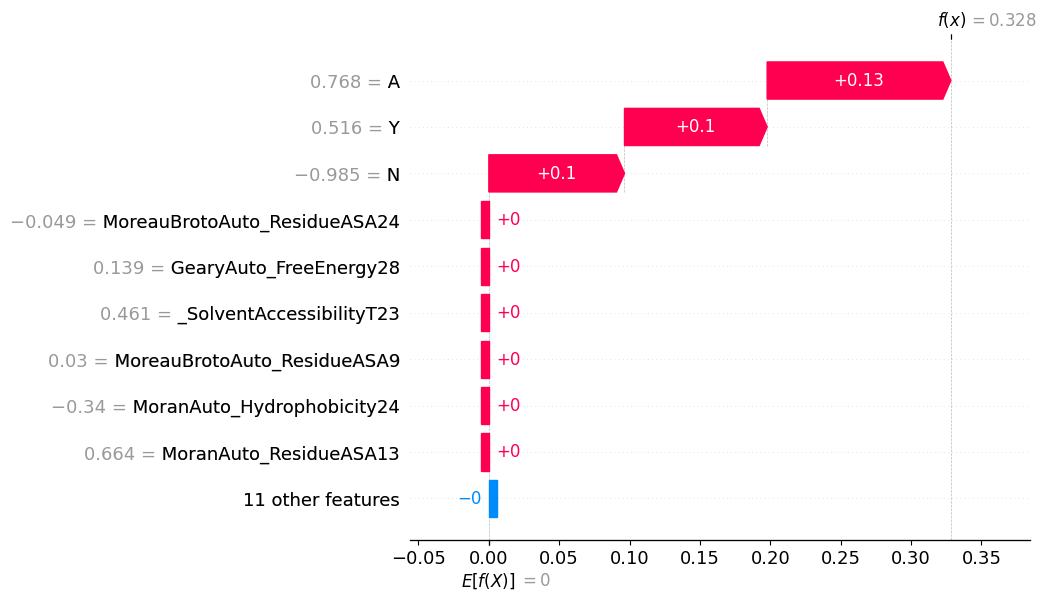

In [ ]:
shap_values_single = shap_values
base_value = explainer.expected_value

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values_single[0, top_idx].squeeze(), # Access the first (and only) sample in shap_values_single
        base_values=base_value,
        data=X_test_feat[i, top_idx],
        feature_names=top_features
    )
)

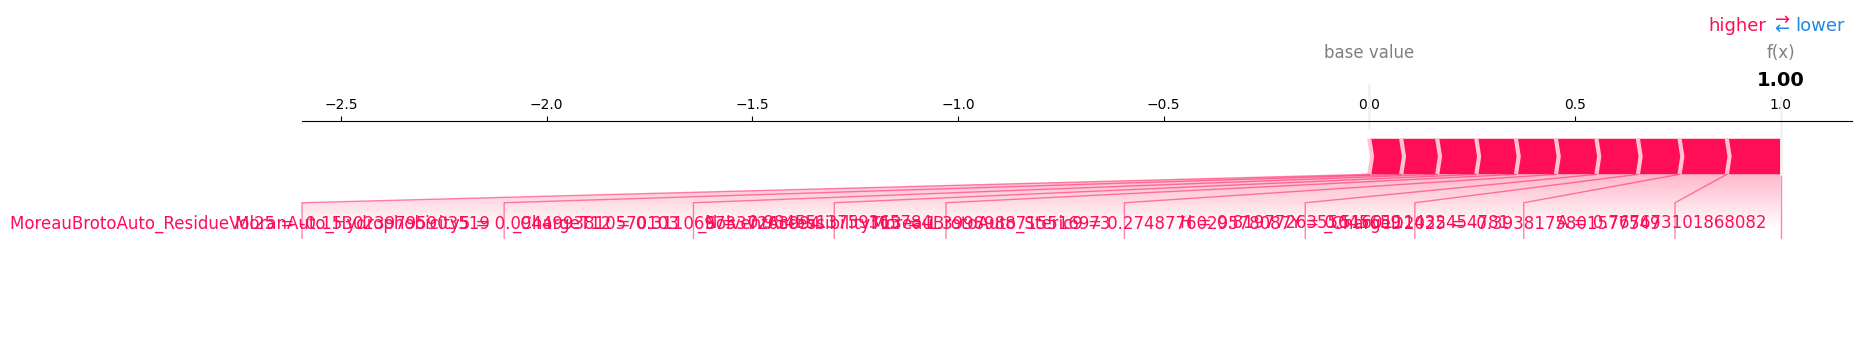

In [ ]:
shap.force_plot(
    base_value,
    shap_values_single[0].squeeze(), # Extract the 1D SHAP values for the single instance
    X_test_feat[i],
    feature_names=columns,
    matplotlib=True
)